In [7]:
"""
red_NN.ipynb - Reto 9 (Data mining)
RNN en PyTorch que predice el payoff de la call asiatica sobre 3 activos.

Entrada: ../DATOS/TRANSFORMADOS/datos_sinteticos.npy  -> forma (100000, 21, 3), precios con S0 = 100.
"""
import os
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm
from scipy.stats.mstats import gmean
from sklearn import metrics
import matplotlib.pyplot as plt
 
try:
    from torch.utils.tensorboard import SummaryWriter
except ImportError:
    SummaryWriter = None
 


In [2]:
%pip install torch scikit-learn scipy

   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.5/124.1 MB 6.7 MB/s eta 0:00:19
   - -------------------------------------- 3.4/124.1 MB 11.3 MB/s eta 0:00:11
   - -------------------------------------- 6.0/124.1 MB 12.3 MB/s eta 0:00:10
   -- ------------------------------------- 7.1/124.1 MB 10.5 MB/s eta 0:00:12
   -- ------------------------------------- 8.4/124.1 MB 8.9 MB/s eta 0:00:13
   --- ------------------------------------ 10.7/124.1 MB 9.6 MB/s eta 0:00:12
   ---- ----------------------------------- 14.2/124.1 MB 10.6 MB/s eta 0:00:11
   ----- ---------------------------------- 18.1/124.1 MB 11.7 MB/s eta 0:00:10
   ------ --------------------------------- 21.5/124.1 MB 12.3 MB/s eta 0:00:09
   ------- -------------------------------- 23.6/124.1 MB 12.2 MB/s eta 0:00:09
   -------- ------------------------------- 25.4/124.1 MB 11.8 MB/s eta 0:00:09
   --------- ------------------------------ 28.8/124.1 MB

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


Simulaciones: 100000 | % payoffs = 0: 60.7%


[rnn] epoca 1  train loss: 0.4094  valid loss: 0.0653


[rnn] epoca 2  train loss: 0.0665  valid loss: 0.0330


[rnn] epoca 3  train loss: 0.0480  valid loss: 0.0216


[rnn] epoca 4  train loss: 0.0392  valid loss: 0.0248
  Not improving for 1/10 epochs


[rnn] epoca 5  train loss: 0.0347  valid loss: 0.0359
  Not improving for 2/10 epochs


... (384 outputs left out)

[lstm] epoca 135  train loss: 0.0030  valid loss: 0.0006
  Not improving for 7/10 epochs


[lstm] epoca 136  train loss: 0.0029  valid loss: 0.0006
  Not improving for 8/10 epochs


[lstm] epoca 137  train loss: 0.0029  valid loss: 0.0006
  Not improving for 9/10 epochs


[lstm] epoca 138  train loss: 0.0029  valid loss: 0.0006
  Not improving for 10/10 epochs
Stopping training

Modelo  Params     RMSE      MAE      R2  Prima real  Prima pred  Err prima
rnn       1217   0.0146   0.0073   0.998      0.1527      0.1543      1.05%
gru       3585   0.0081   0.0036   0.999      0.1527      0.1534      0.49%
lstm      4769   0.0080   0.0036   0.999      0.1527      0.1534      0.44%


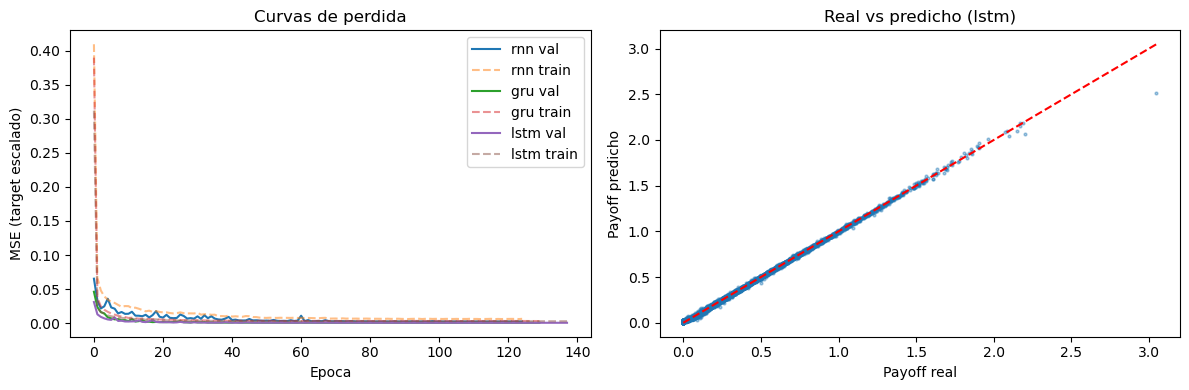

In [14]:
DATA_PATH = os.path.join('..', 'DATOS', 'TRANSFORMADOS', 'datos_sinteticos.npy')
N_SIMS = 100000        # simulaciones usadas (de las 100000); sube para mas calidad
BATCH_SIZE = 256
LR = 0.001
EPOCHS = 150
PATIENCE = 10
UNITS = 32
SEED = 0
CELLS = ['rnn', 'gru', 'lstm']

MU, TTM, N_PASOS, E = 0.01, 5, 20, 3.0
DT = TTM / N_PASOS


def payoff(X):
    """V_T = (suma de las 3 medias geometricas - E)^+"""
    return np.maximum(gmean(X, axis=1).sum(axis=1) - E, 0.0)


def prima(V_T):
    """Prima en t0: payoff descontado."""
    return np.exp(-MU * N_PASOS * DT) * V_T

class RNN(torch.nn.Module):
    def __init__(self, cell, units):
        super().__init__()
        Cell = {'rnn': torch.nn.RNN, 'lstm': torch.nn.LSTM, 'gru': torch.nn.GRU}[cell]
        self.rnn = Cell(3, units, batch_first=True)
        self.dropout = torch.nn.Dropout(0.05)
        self.out = torch.nn.Linear(units, 1)

    def forward(self, x):
        h, _ = self.rnn(x)                      
        return self.out(self.dropout(h[:, -1])).squeeze(-1)   # ultimo paso -> payoff


def entrenar(cell, dataloader_train, dataloader_val):
    torch.manual_seed(SEED)
    model = RNN(cell, UNITS)
    criterion = torch.nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3)
    best_path = f'./best_model_{cell}.pt'
    writer = SummaryWriter(f'runs/{cell}') if SummaryWriter is not None else None

    history = {'train': [], 'val': []}
    min_val_loss = float('inf')
    count = 0

    for epoch in range(EPOCHS):
        model.train()
        training_loss = 0.
        for inputs, targets in tqdm(dataloader_train, desc=f'{cell} epoch {epoch+1} train', leave=False):
            optimizer.zero_grad()
            loss = criterion(model(inputs), targets)
            loss.backward()
            optimizer.step()
            training_loss += loss.item() * inputs.size(0)
        training_loss /= len(dataloader_train.dataset)

        model.eval()
        val_loss = 0.
        with torch.no_grad():
            for inputs, targets in dataloader_val:
                val_loss += criterion(model(inputs), targets).item() * inputs.size(0)
        val_loss /= len(dataloader_val.dataset)
        scheduler.step(val_loss)

        print(f'[{cell}] epoca {epoch+1}  train loss: {training_loss:.4f}  valid loss: {val_loss:.4f}')
        history['train'].append(training_loss)
        history['val'].append(val_loss)
        if writer is not None:
            writer.add_scalar('Loss/train', training_loss, epoch + 1)
            writer.add_scalar('Loss/val', val_loss, epoch + 1)
            writer.flush()

        if val_loss <= min_val_loss:
            min_val_loss = val_loss
            count = 0
            torch.save(model.state_dict(), best_path)
        else:
            count += 1
            print(f'  Not improving for {count}/{PATIENCE} epochs')
            if count >= PATIENCE:
                print('Stopping training')
                break

    if writer is not None:
        writer.close()
    model.load_state_dict(torch.load(best_path))   # restaura el mejor checkpoint
    model.eval()
    return model, history


def evaluar(model, X_te, y_te, ys):
    with torch.no_grad():
        pred = model(X_te).numpy() * ys
    pred = np.maximum(pred, 0.0)                   # el payoff no puede ser negativo
    real = y_te.numpy() * ys
    rmse = np.sqrt(metrics.mean_squared_error(real, pred))
    mae = metrics.mean_absolute_error(real, pred)
    r2 = metrics.r2_score(real, pred)
    p_real, p_pred = prima(real).mean(), prima(pred).mean()
    err_prima = 100 * (p_pred - p_real) / p_real
    return dict(RMSE=rmse, MAE=mae, R2=r2, prima_real=p_real,
                prima_pred=p_pred, err_prima=err_prima, real=real, pred=pred)


if __name__ == '__main__':
    torch.manual_seed(SEED)

    data = np.load(DATA_PATH)
    idx = torch.randperm(len(data))[:N_SIMS].numpy()
    data = data[idx]
    X_ratio = data[:, 1:, :] / data[:, :1, :]                 # (n, 20, 3)
    y = payoff(X_ratio)
    X = np.diff(np.log(X_ratio), axis=1, prepend=0.0)         # log-retornos por paso
    print(f'Simulaciones: {len(X)} | % payoffs = 0: {100 * np.mean(y == 0):.1f}%')

    n_tr, n_val = int(.70 * len(X)), int(.15 * len(X))
    sl_tr, sl_val, sl_te = slice(0, n_tr), slice(n_tr, n_tr + n_val), slice(n_tr + n_val, None)

    m, s = X[sl_tr].mean((0, 1)), X[sl_tr].std((0, 1))
    ys = y[sl_tr].std()
    to_t = lambda a: torch.tensor(a, dtype=torch.float32)
    X_s, y_s = to_t((X - m) / s), to_t(y / ys)

    dataset_train = TensorDataset(X_s[sl_tr], y_s[sl_tr])
    dataset_val = TensorDataset(X_s[sl_val], y_s[sl_val])
    dataloader_train = DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True)
    dataloader_val = DataLoader(dataset_val, batch_size=BATCH_SIZE)
    X_te, y_te = X_s[sl_te], y_s[sl_te]

    resultados, historias = {}, {}
    for cell in CELLS:
        model, historias[cell] = entrenar(cell, dataloader_train, dataloader_val)
        n_par = sum(p.numel() for p in model.parameters())
        resultados[cell] = evaluar(model, X_te, y_te, ys)
        resultados[cell]['params'] = n_par

    print(f"\n{'Modelo':<6} {'Params':>7} {'RMSE':>8} {'MAE':>8} {'R2':>7} "
          f"{'Prima real':>11} {'Prima pred':>11} {'Err prima':>10}")
    for cell, r in resultados.items():
        print(f"{cell:<6} {r['params']:>7} {r['RMSE']:>8.4f} {r['MAE']:>8.4f} {r['R2']:>7.3f} "
              f"{r['prima_real']:>11.4f} {r['prima_pred']:>11.4f} {r['err_prima']:>9.2f}%")

    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    for cell, h in historias.items():
        axs[0].plot(h['val'], label=f'{cell} val')
        axs[0].plot(h['train'], '--', alpha=.5, label=f'{cell} train')
    axs[0].set_xlabel('Epoca')
    axs[0].set_ylabel('MSE (target escalado)')
    axs[0].set_title('Curvas de perdida')
    axs[0].legend()

    mejor = min(resultados, key=lambda c: resultados[c]['RMSE'])
    r = resultados[mejor]
    axs[1].scatter(r['real'], r['pred'], s=4, alpha=.4)
    lim = [0, max(r['real'].max(), r['pred'].max())]
    axs[1].plot(lim, lim, 'r--')
    axs[1].set_xlabel('Payoff real')
    axs[1].set_ylabel('Payoff predicho')
    axs[1].set_title(f'Real vs predicho ({mejor})')
    plt.tight_layout()
    plt.savefig('resultados_rnn.png', dpi=150)
    plt.show()